# Chronos-2 Electricity Forecasting: Zero-Shot Evaluation

## Overview

This notebook evaluates the pretrained Chronos-2 model on the hourly Electricity dataset without additional fine-tuning.

The main tasks performed in this notebook are:

- Loading the prepared training, validation, and test datasets.
- Loading the pretrained Chronos-2 model.
- Testing the model on an individual customer time series.
- Evaluating zero-shot forecasting performance across all 321 customer series.
- Calculating MAE, RMSE, and MASE metrics.
- Comparing Chronos-2 against a seasonal naive baseline.
- Saving the evaluation results for subsequent comparison with the fine-tuned model.

## 1. Environment Setup and Loading Prepared Data

Google Drive is mounted to access the dataset splits saved during the data preparation stage.

The training, validation, and test sets are loaded from the saved NumPy archive. These prepared splits are reused throughout the notebook to ensure consistency in the evaluation process.

The required Python libraries are imported, and the Chronos forecasting package is installed to enable loading and running the pretrained Chronos-2 model.

In [ ]:
from google.colab import drive, files
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

In [1]:
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
save_dir = "/content/drive/MyDrive/Chronos2_Finetune"

saved = np.load(
    f"{save_dir}/dataset_splits.npz"
)

train_data = saved["train"]
val_data = saved["val"]
test_data = saved["test"]

print(len(train_data), len(val_data), len(test_data))

321 321 321


In [5]:
uploaded = files.upload()

Saving seasonal_naive_baseline.csv to seasonal_naive_baseline.csv
Saving baseline_comparison.csv to baseline_comparison.csv
Saving chronos2_zero_shot_baseline.csv to chronos2_zero_shot_baseline.csv


## 2. Loading the Pretrained Chronos-2 Model

The pretrained Chronos-2 model is loaded using the `Chronos2Pipeline` interface.

The model is loaded onto the available CUDA device to enable GPU-based inference.

Its configuration is inspected to identify the supported forecast quantiles, including the median (0.5) quantile used for point forecasting.

In [ ]:
!pip install -q chronos-forecasting

In [ ]:
from chronos import Chronos2Pipeline

# Load the pretrained Chronos-2 model
pipeline = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map="cuda"
)

print("Chronos-2 loaded successfully!")
print("Device:", pipeline.model.device)

In [ ]:
print(pipeline.model.config)

print("\nConfiguration attributes:")
print(pipeline.model.config.to_dict().keys())

Chronos2CoreConfig {
  "architectures": [
    "Chronos2Model"
  ],
  "chronos_config": {
    "context_length": 8192,
    "input_patch_size": 16,
    "input_patch_stride": 16,
    "max_output_patches": 64,
    "output_patch_size": 16,
    "quantiles": [
      0.01,
      0.05,
      0.1,
      0.15,
      0.2,
      0.25,
      0.3,
      0.35,
      0.4,
      0.45,
      0.5,
      0.55,
      0.6,
      0.65,
      0.7,
      0.75,
      0.8,
      0.85,
      0.9,
      0.95,
      0.99
    ],
    "time_encoding_scale": 8192,
    "use_arcsinh": true,
    "use_reg_token": true
  },
  "chronos_pipeline_class": "Chronos2Pipeline",
  "d_ff": 3072,
  "d_kv": 64,
  "d_model": 768,
  "dense_act_fn": "relu",
  "dropout_rate": 0.1,
  "dtype": "float32",
  "feed_forward_proj": "relu",
  "initializer_factor": 0.05,
  "is_gated_act": false,
  "layer_norm_epsilon": 1e-06,
  "model_type": "t5",
  "num_heads": 12,
  "num_layers": 12,
  "pad_token_id": 0,
  "reg_token_id": 1,
  "rope_theta": 10000.

## 3. Single-Series Zero-Shot Forecasting

Before evaluating all customer time series, a sample forecast is generated using the first customer series (T1).

The pretrained Chronos-2 model receives the most recent 168 hours of training observations as context and generates a 24-hour forecast.

The median (0.5) forecast quantile is extracted and compared with the corresponding actual observations from the validation set.

Forecast performance is assessed using Mean Absolute Error (MAE), alongside a visual comparison of predicted and actual electricity consumption.

In [ ]:
# Use the first 168 hours of T1 as historical context
context = torch.tensor(
    train_data[0][-168:],
    dtype=torch.float32
).unsqueeze(0).unsqueeze(0)

# Generate a 24-hour forecast
forecast = pipeline.predict(
    context,
    prediction_length=24
)

print("Context shape:", context.shape)
print("Output type:", type(forecast))
print("Number of outputs:", len(forecast))
print("First output type:", type(forecast[0]))
print("First output shape:", forecast[0].shape)

Context shape: torch.Size([1, 1, 168])
Output type: <class 'list'>
Number of outputs: 1
First output type: <class 'torch.Tensor'>
First output shape: torch.Size([1, 21, 24])


In [ ]:
quantiles = pipeline.model.config.chronos_config["quantiles"]

# Extract the median forecast for T1
median_index = quantiles.index(0.5)
median_forecast = forecast[0][0, median_index, :].cpu().numpy()

# Actual observations immediately after the training period
actual = val_data[0][:24]

print("Median forecast:", median_forecast.shape)
print("Actual values:", actual.shape)

Median forecast: (24,)
Actual values: (24,)


In [ ]:
mae = mean_absolute_error(actual, median_forecast)

print(f"Zero-shot MAE: {mae:.4f}")

Zero-shot MAE: 2.8961


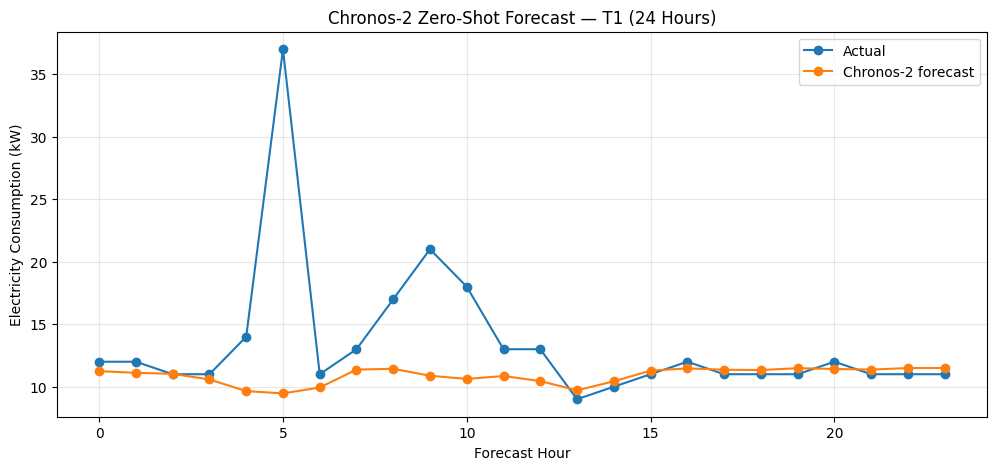

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(actual, label="Actual", marker="o")
plt.plot(median_forecast, label="Chronos-2 forecast", marker="o")

plt.title("Chronos-2 Zero-Shot Forecast — T1 (24 Hours)")
plt.xlabel("Forecast Hour")
plt.ylabel("Electricity Consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
median_index = quantiles.index(0.5)

context_length = 168
horizon = 24

t1_actuals = []
t1_predictions = []

for i in range(len(test_data[0]) // horizon):

    start = i * horizon
    end = start + horizon

    context = np.concatenate([
        train_data[0],
        test_data[0][:start]
    ])[-context_length:]

    actual = test_data[0][start:end]

    context_tensor = torch.tensor(
        context, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)

    forecast = pipeline.predict(
        context_tensor,
        prediction_length=horizon
    )

    prediction = forecast[0][0, median_index, :].cpu().numpy()

    t1_actuals.extend(actual)
    t1_predictions.extend(prediction)

t1_actuals = np.array(t1_actuals)
t1_predictions = np.array(t1_predictions)

mae = mean_absolute_error(t1_actuals, t1_predictions)
rmse = np.sqrt(mean_squared_error(t1_actuals, t1_predictions))

print("T1 Zero-shot MAE:", mae)
print("T1 Zero-shot RMSE:", rmse)
print("Evaluated observations:", len(t1_actuals))

T1 Zero-shot MAE: 5.1685309410095215
T1 Zero-shot RMSE: 12.620988567342582
Evaluated observations: 3936


## 4. Zero-Shot Evaluation Across All Customer Series

The pretrained Chronos-2 model is evaluated across all 321 customer time series using a rolling-origin forecasting approach.

The evaluation uses the following configuration:

- Context length: 168 hours (7 days).
- Forecast horizon: 24 hours.
- Forecast quantile: 0.5 (median).
- Forecasting windows: Non-overlapping 24-hour periods.

At each forecast origin, the model uses the most recent 168 available observations to predict the next 24 hours. Previously observed test values are incorporated into subsequent forecasting contexts.

MAE and RMSE are calculated for each customer series and aggregated to assess the model's overall zero-shot forecasting performance.

In [ ]:
import time

quantiles = pipeline.model.config.chronos_config["quantiles"]
median_index = quantiles.index(0.5)

context_length = 168
horizon = 24
num_windows = len(test_data[0]) // horizon

results = []
start_time = time.time()

for series_idx in range(len(test_data)):

    actuals = []
    predictions = []

    for i in range(num_windows):

        start = i * horizon
        end = start + horizon

        context = np.concatenate([
            train_data[series_idx],
            test_data[series_idx][:start]
        ])[-context_length:]

        actual = test_data[series_idx][start:end]

        context_tensor = torch.tensor(
            context, dtype=torch.float32
        ).unsqueeze(0).unsqueeze(0)

        forecast = pipeline.predict(
            context_tensor,
            prediction_length=horizon
        )

        prediction = forecast[0][0, median_index, :].cpu().numpy()

        actuals.extend(actual)
        predictions.extend(prediction)

    actuals = np.array(actuals)
    predictions = np.array(predictions)

    mae = mean_absolute_error(actuals, predictions)
    rmse = np.sqrt(mean_squared_error(actuals, predictions))

    results.append({
        "series_id": series_data[series_idx]["series_id"],
        "MAE": mae,
        "RMSE": rmse
    })

    if (series_idx + 1) % 10 == 0:
        print(
            f"Completed {series_idx + 1}/{len(test_data)} series | "
            f"Elapsed: {(time.time() - start_time)/60:.1f} min"
        )

zero_shot_results = pd.DataFrame(results)

print("\nEvaluation complete.")
print("Total time:", round((time.time() - start_time)/60, 2), "minutes")
print(zero_shot_results.head())

Completed 10/321 series | Elapsed: 1.0 min
Completed 20/321 series | Elapsed: 1.9 min
Completed 30/321 series | Elapsed: 2.7 min
Completed 40/321 series | Elapsed: 3.6 min
Completed 50/321 series | Elapsed: 4.4 min
Completed 60/321 series | Elapsed: 5.3 min
Completed 70/321 series | Elapsed: 6.1 min
Completed 80/321 series | Elapsed: 7.0 min
Completed 90/321 series | Elapsed: 7.9 min
Completed 100/321 series | Elapsed: 8.7 min
Completed 110/321 series | Elapsed: 9.6 min
Completed 120/321 series | Elapsed: 10.4 min
Completed 130/321 series | Elapsed: 11.3 min
Completed 140/321 series | Elapsed: 12.2 min
Completed 150/321 series | Elapsed: 13.0 min
Completed 160/321 series | Elapsed: 13.9 min
Completed 170/321 series | Elapsed: 14.7 min
Completed 180/321 series | Elapsed: 15.6 min
Completed 190/321 series | Elapsed: 16.4 min
Completed 200/321 series | Elapsed: 17.3 min
Completed 210/321 series | Elapsed: 18.1 min
Completed 220/321 series | Elapsed: 19.0 min
Completed 230/321 series | Ela

## 5. Evaluation Metrics and Performance Analysis

The zero-shot forecasting results are analysed using three evaluation metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual consumption.
- **Root Mean Squared Error (RMSE):** Measures prediction errors while assigning greater weight to larger errors.
- **Mean Absolute Scaled Error (MASE):** Compares forecasting errors against a seasonal naive benchmark based on the training data.

Metrics are calculated for each customer series and summarised using their mean and median values to assess overall performance and variation across customers.

In [ ]:
print("Mean MAE:", zero_shot_results["MAE"].mean())
print("Median MAE:", zero_shot_results["MAE"].median())

print("Mean RMSE:", zero_shot_results["RMSE"].mean())
print("Median RMSE:", zero_shot_results["RMSE"].median())

print("\nBest 5 series:")
print(zero_shot_results.nsmallest(5, "MAE"))

print("\nWorst 5 series:")
print(zero_shot_results.nlargest(5, "MAE"))

Mean MAE: 170.4269072723567
Median MAE: 43.13868713378906
Mean RMSE: 323.58053212372505
Median RMSE: 70.78968975621555

Best 5 series:
    series_id           MAE          RMSE
182      T183  9.511116e-10  1.252692e-09
2          T3  5.807950e-01  1.433557e+00
298      T299  1.568095e+00  6.390484e+00
114      T115  2.118407e+00  6.771313e+00
122      T123  2.828720e+00  6.234991e+00

Worst 5 series:
    series_id           MAE          RMSE
313      T314  16349.583008  35253.250630
155      T156   4807.109863   8261.379546
236      T237   2938.125000   5230.009178
167      T168   1227.808350   2092.057839
315      T316   1198.021362   2764.690941


### 5.1 Investigating Selected Customer Series

Selected customer series are examined to understand differences in forecasting performance.

The analysis focuses on their consumption statistics, helping identify unusual patterns and potential reasons for higher forecasting errors.

In [ ]:
for idx in [182, 313, 155, 236, 167, 315]:
    train = train_data[idx]
    test = test_data[idx]

    print(f"\n{series_data[idx]['series_id']}")
    print("Train mean:", np.mean(train))
    print("Train std:", np.std(train))
    print("Train min/max:", np.min(train), np.max(train))
    print("Test mean:", np.mean(test))
    print("Test std:", np.std(test))
    print("Test min/max:", np.min(test), np.max(test))
    print("Unique test values:", len(np.unique(test)))


T183
Train mean: 1031.398
Train std: 1496.7036
Train min/max: 0.0 5180.0
Test mean: 0.0
Test std: 0.0
Test min/max: 0.0 0.0
Unique test values: 1

T314
Train mean: 200907.67
Train std: 145555.17
Train min/max: 0.0 764000.0
Test mean: 220427.97
Test std: 163372.95
Test min/max: 32300.0 672400.0
Unique test values: 2320

T156
Train mean: 79607.87
Train std: 26499.043
Train min/max: 0.0 173669.0
Test mean: 78905.14
Test std: 25974.336
Test min/max: 33251.0 203001.0
Unique test values: 2524

T237
Train mean: 45988.56
Train std: 11892.771
Train min/max: 420.0 78721.0
Test mean: 47274.754
Test std: 10325.8955
Test min/max: 0.0 71619.0
Unique test values: 1372

T168
Train mean: 25443.75
Train std: 7262.816
Train min/max: 0.0 48843.0
Test mean: 26272.121
Test std: 7638.4443
Test min/max: 0.0 44161.0
Unique test values: 2966

T316
Train mean: 16017.943
Train std: 9843.207
Train min/max: 0.0 39728.0
Test mean: 15660.852
Test std: 10136.572
Test min/max: 0.0 32524.0
Unique test values: 1848


In [ ]:
mase_results = []

for i in range(len(train_data)):
    train = train_data[i]

    scale = np.mean(np.abs(train[24:] - train[:-24]))

    mae = zero_shot_results.loc[i, "MAE"]

    mase = mae / scale if scale > 0 else np.nan

    mase_results.append(mase)

zero_shot_results["MASE"] = mase_results

print("Mean MASE:", zero_shot_results["MASE"].mean())
print("Median MASE:", zero_shot_results["MASE"].median())
print("Series with MASE < 1:",
      (zero_shot_results["MASE"] < 1).sum())
print("Series with MASE > 1:",
      (zero_shot_results["MASE"] > 1).sum())
print("Undefined MASE:",
      zero_shot_results["MASE"].isna().sum())

Mean MASE: 0.8181302845385465
Median MASE: 0.8233452916493001
Series with MASE < 1: 279
Series with MASE > 1: 42
Undefined MASE: 0


In [ ]:
summary = zero_shot_results[["MAE", "RMSE", "MASE"]].agg(
    ["mean", "median", "min", "max"]
)

display(summary)

,MAE,RMSE,MASE
mean,1.704269e+02,3.235805e+02,8.181303e-01
median,4.313869e+01,7.078969e+01,8.233453e-01
min,9.511116e-10,1.252692e-09,1.731780e-11
max,1.634958e+04,3.525325e+04,2.324834e+00


In [ ]:
weak_series = zero_shot_results[
    zero_shot_results["MASE"] > 1
].sort_values("MASE", ascending=False)

display(weak_series.head(10))

,series_id,MAE,RMSE,MASE
245,T246,49.025059,112.834983,2.324834
114,T115,2.118407,6.771313,1.637104
316,T317,48.248451,86.486988,1.481155
287,T288,41.489792,80.098209,1.392489
146,T147,24.227783,39.294525,1.382863
147,T148,8.756463,19.493070,1.363276
297,T298,104.747871,195.821497,1.316818
83,T84,78.292999,193.548111,1.266159
111,T112,47.274082,67.046604,1.209303
57,T58,21.957996,32.560729,1.208595


## 6. Seasonal Naive Baseline Comparison

A seasonal naive forecasting model is implemented as a baseline for comparison with Chronos-2.

The baseline uses the most recent 24-hour consumption pattern to predict the next 24 hours. This assumes that daily electricity consumption patterns repeat over time.

The seasonal naive model is evaluated across all 321 customer series using the same test periods and forecasting horizon as Chronos-2.

MAE and RMSE are calculated for each series, and the results are compared with the zero-shot Chronos-2 predictions to assess their relative performance.

In [ ]:
seasonal_results = []

for i in range(len(test_data)):

    actuals = []
    predictions = []

    for j in range(len(test_data[i]) // 24):

        start = j * 24
        end = start + 24

        context = np.concatenate([
            train_data[i],
            test_data[i][:start]
        ])

        prediction = context[-24:]
        actual = test_data[i][start:end]

        actuals.extend(actual)
        predictions.extend(prediction)

    actuals = np.array(actuals)
    predictions = np.array(predictions)

    seasonal_results.append({
        "series_id": series_data[i]["series_id"],
        "MAE": mean_absolute_error(actuals, predictions),
        "RMSE": np.sqrt(mean_squared_error(actuals, predictions))
    })

seasonal_results = pd.DataFrame(seasonal_results)

print("Mean MAE:", seasonal_results["MAE"].mean())
print("Median MAE:", seasonal_results["MAE"].median())
print("Mean RMSE:", seasonal_results["RMSE"].mean())
print("Median RMSE:", seasonal_results["RMSE"].median())

Mean MAE: 210.59933483656323
Median MAE: 54.5093994140625
Mean RMSE: 374.2499678396495
Median RMSE: 95.84770838744659


In [ ]:
comparison = zero_shot_results.merge(
    seasonal_results,
    on="series_id",
    suffixes=("_chronos", "_naive")
)

comparison["Chronos_better"] = (
    comparison["MAE_chronos"] < comparison["MAE_naive"]
)

print("Chronos wins:",
      comparison["Chronos_better"].sum())

print("Seasonal-naive wins:",
      (~comparison["Chronos_better"]).sum())

print("Chronos win rate:",
      comparison["Chronos_better"].mean() * 100, "%")

Chronos wins: 318
Seasonal-naive wins: 3
Chronos win rate: 99.06542056074767 %


## 7. Saving Evaluation Results

The evaluation results are saved as CSV files for use in subsequent analysis and comparison with the fine-tuned Chronos-2 model.

The following outputs are saved:

- `chronos2_zero_shot_baseline.csv`: Zero-shot evaluation metrics for all customer series.
- `seasonal_naive_baseline.csv`: Seasonal naive baseline metrics.
- `baseline_comparison.csv`: Comparative results showing the performance of both forecasting approaches.

These files provide the baseline results for evaluating the impact of LoRA fine-tuning.

In [ ]:
zero_shot_results.to_csv(
    "chronos2_zero_shot_baseline.csv", index=False
)

seasonal_results.to_csv(
    "seasonal_naive_baseline.csv", index=False
)

comparison.to_csv(
    "baseline_comparison.csv", index=False
)